# Etapa 4 — Modelagem: risco de morte em acidentes nas BRs de Pernambuco

**Projeto de Parceria Semantix · EBAC** — Eduardo Costa

## Problema de negócio

Em 2025 a PRF registrou 3.013 acidentes nas rodovias federais de Pernambuco, com 336 mortes. Só 1 em cada 10 acidentes tem morte, mas esses poucos concentram quase toda a perda de vidas. A PRF, o DNIT e o SAMU têm equipes, viaturas e radares limitados: **saber quais combinações de local, horário, tipo de via e tipo de acidente têm mais risco de terminar em morte** ajuda a decidir onde fiscalizar, onde investir em engenharia (duplicação, iluminação, passarelas) e quais ocorrências priorizar no atendimento.

A análise descritiva (Etapas 2 e 3) mostra fatores isolados. O Machine Learning acrescenta duas coisas:

1. **Classificação supervisionada** — um modelo que combina todos os fatores ao mesmo tempo e devolve uma *probabilidade de morte* para cada acidente, avaliada em meses que o modelo nunca viu.
2. **Segmentação não supervisionada (PCA + K-means)** — agrupa os municípios por perfil de risco, para que cada grupo receba uma estratégia diferente.

Antes de modelar, um **teste de hipóteses** confirma que as diferenças vistas na EDA não são acaso.

**Alvo:** `com_morte` (1 = pelo menos um morto no acidente). Classe positiva ≈ 10% → problema **desbalanceado**; por isso as métricas principais são **PR-AUC** (precisão média) e **recall entre os acidentes de maior risco**, além do ROC-AUC.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, recall_score, precision_score, f1_score)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10})
COR, CINZA, DESTAQUE = '#1f5f8b', '#b0b7bf', '#c0392b'
import os; os.makedirs('05_resultados/figuras', exist_ok=True)

oc = pd.read_csv('03_dados_finais/final_ocorrencias.csv', parse_dates=['data'])
pe = pd.read_csv('03_dados_finais/final_pessoas.csv')
mu = pd.read_csv('03_dados_finais/final_municipios.csv')
print(oc.shape, pe.shape, mu.shape)
print(f"Acidentes com morte: {oc.com_morte.sum()} de {len(oc)} ({oc.com_morte.mean():.1%})")

(3013, 43) (7300, 22) (185, 12)
Acidentes com morte: 302 de 3013 (10.0%)


## 1. Inferência: as diferenças da EDA são estatisticamente significativas?

Teste qui-quadrado de independência (α = 0,05) entre `com_morte` e cada fator, com intervalo de confiança de 95% para a proporção de acidentes com morte em cada grupo.

In [2]:
def ic_prop(k, n, z=1.96):
    # intervalo de Wilson
    p = k / n; d = 1 + z**2/n
    c = (p + z**2/(2*n)) / d; m = z*np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return c - m, c + m

oc['madrugada'] = oc.hora.between(0, 5).map({True: 'Madrugada (0-5h)', False: 'Demais horários'})
testes = []
for fator in ['madrugada', 'tipo_pista', 'fase_dia', 'fim_de_semana', 'condicao_metereologica']:
    tab = pd.crosstab(oc[fator], oc.com_morte)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    n = len(oc); k = min(tab.shape) - 1
    testes.append({'fator': fator, 'qui2': round(chi2, 1), 'gl': dof, 'p_valor': p,
                   'V_de_Cramer': round(np.sqrt(chi2 / (n * k)), 3), 'significativo': p < 0.05})
testes = pd.DataFrame(testes); testes['p_valor'] = testes.p_valor.map(lambda v: f'{v:.1e}')
print(testes.to_string(index=False))

print('\n% de acidentes com morte por grupo (IC 95%):')
for fator in ['madrugada', 'tipo_pista']:
    g = oc.groupby(fator).com_morte.agg(['sum', 'size'])
    for nome, r in g.iterrows():
        lo, hi = ic_prop(r['sum'], r['size'])
        print(f"  {nome:<18} {r['sum']/r['size']:6.1%}  [{lo:.1%} – {hi:.1%}]  n={r['size']}")

                 fator  qui2  gl p_valor  V_de_Cramer  significativo
             madrugada  41.8   1 1.0e-10        0.118           True
            tipo_pista 109.0   2 2.2e-24        0.190           True
              fase_dia  64.9   3 5.2e-14        0.147           True
         fim_de_semana  11.0   1 9.3e-04        0.060           True
condicao_metereologica  13.3   7 6.5e-02        0.066          False

% de acidentes com morte por grupo (IC 95%):
  Demais horários      8.8%  [7.8% – 9.9%]  n=2689
  Madrugada (0-5h)    20.4%  [16.3% – 25.1%]  n=324
  Dupla                6.0%  [5.0% – 7.3%]  n=1608
  Múltipla             5.1%  [3.2% – 7.9%]  n=356
  Simples             17.8%  [15.6% – 20.3%]  n=1049


## 2. Preparação dos dados e prevenção de vazamento

**Variáveis excluídas por vazamento** (só são conhecidas *depois* do desfecho, ou são o próprio desfecho): `mortos`, `feridos*`, `ilesos`, `ignorados`, `classificacao_acidente`, `gravidade`, `estado_fisico` e `vitima_fatal` da tabela de pessoas.

**Variáveis usadas** (conhecidas no momento do registro do acidente): local (BR, km, latitude/longitude, delegacia), tempo (hora, dia da semana, mês, fase do dia), via (tipo de pista, traçado, área urbana), clima, tipo e causa do acidente, nº de pessoas e veículos — mais 5 indicadores criados a partir da tabela de pessoas: **moto, pedestre, caminhão, ônibus e bicicleta envolvidos**.

**Divisão temporal:** treino = jan–set/2025, teste = out–dez/2025. Isso simula o uso real (treinar no passado, prever o futuro) e evita que acidentes do mesmo período apareçam nos dois lados. Codificação, padronização e imputação ficam **dentro do Pipeline**, então são ajustadas só no treino a cada dobra da validação cruzada.

In [3]:
# indicadores de envolvidos (presença, não desfecho)
veic = pe.drop_duplicates(['id', 'id_veiculo'])
flags = pd.DataFrame({
    'tem_moto':      veic[veic.grupo_veiculo == 'Moto'].groupby('id').size(),
    'tem_caminhao':  veic[veic.grupo_veiculo == 'Caminhão'].groupby('id').size(),
    'tem_onibus':    veic[veic.grupo_veiculo == 'Ônibus/Micro-ônibus'].groupby('id').size(),
    'tem_bicicleta': veic[veic.grupo_veiculo == 'Bicicleta'].groupby('id').size(),
    'tem_pedestre':  pe[pe.tipo_envolvido == 'Pedestre'].groupby('id').size(),
}).gt(0).astype(int)
df = oc.merge(flags, left_on='id', right_index=True, how='left')
df[flags.columns] = df[flags.columns].fillna(0).astype(int)

# traçado da via: texto composto ("Aclive;curva") -> indicadores
trac = df.tracado_via.str.lower()
for nome, termo in {'curva': 'curva', 'declive': 'declive', 'aclive': 'aclive', 'intersecao': 'interse',
                    'retorno': 'retorno', 'viaduto_ponte': 'viaduto|ponte', 'rotatoria': 'rotat'}.items():
    df[f'trac_{nome}'] = trac.str.contains(termo).astype(int)

# hora cíclica (23h fica perto de 0h)
df['hora_sin'] = np.sin(2*np.pi*df.hora/24); df['hora_cos'] = np.cos(2*np.pi*df.hora/24)
df['br'] = df.br_nome

NUM = ['km', 'latitude', 'longitude', 'pessoas', 'veiculos', 'hora_sin', 'hora_cos', 'dia_semana_num', 'mes'] \
      + list(flags.columns) + [c for c in df if c.startswith('trac_')]
CAT = ['br', 'delegacia', 'fase_dia', 'tipo_pista', 'uso_solo', 'condicao_metereologica',
       'tipo_acidente', 'causa_acidente', 'sentido_via', 'fim_de_semana']
ALVO = 'com_morte'

treino, teste = df[df.mes <= 9], df[df.mes >= 10]
Xtr, ytr, Xte, yte = treino[NUM + CAT], treino[ALVO], teste[NUM + CAT], teste[ALVO]
print(f'Treino: {len(Xtr)} acidentes ({ytr.mean():.1%} com morte) | Teste: {len(Xte)} ({yte.mean():.1%})')
print(f'{len(NUM)} variáveis numéricas + {len(CAT)} categóricas')
print(df[flags.columns].mean().map('{:.1%}'.format).to_string())

Treino: 2154 acidentes (10.6% com morte) | Teste: 859 (8.5%)
21 variáveis numéricas + 10 categóricas
tem_moto         54.8%
tem_caminhao     20.7%
tem_onibus        5.3%
tem_bicicleta     2.6%
tem_pedestre      6.5%


## 3. Comparação de modelos com validação cruzada

5 dobras estratificadas no conjunto de treino. Modelos:

| Modelo | Por que testar |
| --- | --- |
| Dummy (sempre a classe majoritária) | linha de base — qualquer modelo útil precisa superá-la |
| Regressão Logística (balanceada, L2) | simples, interpretável (razões de chance) |
| Random Forest (balanceada) | captura interações não lineares |
| Gradient Boosting (HistGradientBoosting) | costuma ser o mais forte em dados tabulares |
| **Combinação (Voting, média das probabilidades)** | combinação de modelos: junta o viés baixo das árvores com a estabilidade da logística |

In [4]:
def preprocessador(escalar=True):
    num = [('imp', SimpleImputer(strategy='median'))] + ([('esc', StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ('num', Pipeline(num), NUM),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=15, sparse_output=False), CAT)])

modelos = {
    'Dummy': Pipeline([('prep', preprocessador()), ('clf', DummyClassifier(strategy='prior'))]),
    'Regressão Logística': Pipeline([('prep', preprocessador()),
        ('clf', LogisticRegression(C=0.3, class_weight='balanced', max_iter=3000))]),
    'Random Forest': Pipeline([('prep', preprocessador(False)),
        ('clf', RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight='balanced_subsample',
                                       n_jobs=-1, random_state=SEED))]),
    'Gradient Boosting': Pipeline([('prep', preprocessador(False)),
        ('clf', HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=300,
                                               class_weight='balanced', random_state=SEED))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res = {}
for nome, m in modelos.items():
    auc = cross_val_score(m, Xtr, ytr, cv=cv, scoring='roc_auc')
    ap = cross_val_score(m, Xtr, ytr, cv=cv, scoring='average_precision')
    res[nome] = {'ROC-AUC': auc.mean(), 'ROC-AUC dp': auc.std(), 'PR-AUC': ap.mean(), 'PR-AUC dp': ap.std()}
    print(f'{nome:<22} ROC-AUC {auc.mean():.3f} ± {auc.std():.3f} | PR-AUC {ap.mean():.3f} ± {ap.std():.3f}')

Dummy                  ROC-AUC 0.500 ± 0.000 | PR-AUC 0.106 ± 0.001
Regressão Logística    ROC-AUC 0.779 ± 0.046 | PR-AUC 0.337 ± 0.053
Random Forest          ROC-AUC 0.779 ± 0.047 | PR-AUC 0.365 ± 0.073
Gradient Boosting      ROC-AUC 0.758 ± 0.055 | PR-AUC 0.360 ± 0.067


## 4. Otimização de hiperparâmetros

`RandomizedSearchCV` (25 combinações × 5 dobras) para os três modelos, otimizando **PR-AUC** — a métrica que mais importa quando a classe de interesse é rara. Tudo só no treino.

In [5]:
busca = {
    'Regressão Logística': {'clf__C': np.logspace(-3, 1, 30)},
    'Random Forest': {'clf__n_estimators': [300, 500, 800], 'clf__max_depth': [None, 6, 10, 16],
                      'clf__min_samples_leaf': [1, 3, 5, 10, 20], 'clf__max_features': ['sqrt', 0.2, 0.35]},
    'Gradient Boosting': {'clf__learning_rate': [0.02, 0.03, 0.05, 0.1], 'clf__max_depth': [2, 3, 4, 6, None],
                          'clf__max_iter': [150, 300, 500], 'clf__min_samples_leaf': [10, 20, 40, 80],
                          'clf__l2_regularization': [0, 0.1, 1, 5]},
}
melhores = {}
for nome, grade in busca.items():
    s = RandomizedSearchCV(modelos[nome], grade, n_iter=min(25,np.prod([len(v) for v in grade.values()])),
                           scoring='average_precision', cv=cv, random_state=SEED, n_jobs=-1)
    s.fit(Xtr, ytr)
    melhores[nome] = s.best_estimator_
    print(f'{nome:<22} PR-AUC (CV) {s.best_score_:.3f}  ->  {s.best_params_}')

melhores['Combinação (Voting)'] = VotingClassifier(
    [('lr', melhores['Regressão Logística']), ('rf', melhores['Random Forest']), ('gb', melhores['Gradient Boosting'])],
    voting='soft')
for nome in ['Combinação (Voting)']:
    ap = cross_val_score(melhores[nome], Xtr, ytr, cv=cv, scoring='average_precision')
    auc = cross_val_score(melhores[nome], Xtr, ytr, cv=cv, scoring='roc_auc')
    print(f'{nome:<22} PR-AUC (CV) {ap.mean():.3f} ± {ap.std():.3f} | ROC-AUC {auc.mean():.3f}')

cv_final = {}
for nome, m in melhores.items():
    cv_final[nome] = {'PR-AUC': cross_val_score(m, Xtr, ytr, cv=cv, scoring='average_precision').mean(),
                      'ROC-AUC': cross_val_score(m, Xtr, ytr, cv=cv, scoring='roc_auc').mean()}
cv_final = pd.DataFrame(cv_final).T.sort_values('PR-AUC', ascending=False)
print('\n', cv_final.round(3))

Regressão Logística    PR-AUC (CV) 0.359  ->  {'clf__C': np.float64(0.017433288221999882)}
Random Forest          PR-AUC (CV) 0.373  ->  {'clf__n_estimators': 300, 'clf__min_samples_leaf': 10, 'clf__max_features': 0.2, 'clf__max_depth': None}
Gradient Boosting      PR-AUC (CV) 0.389  ->  {'clf__min_samples_leaf': 10, 'clf__max_iter': 150, 'clf__max_depth': 2, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0}
Combinação (Voting)    PR-AUC (CV) 0.392 ± 0.084 | ROC-AUC 0.796

                      PR-AUC  ROC-AUC
Combinação (Voting)   0.392    0.796
Gradient Boosting     0.389    0.788
Random Forest         0.373    0.771
Regressão Logística   0.359    0.792


## 5. Avaliação final no conjunto de teste (out–dez/2025)

O teste é usado **uma única vez**, depois de todas as escolhas. O limiar de decisão é definido no treino (previsões fora da dobra), não no teste: escolhemos o limiar que coloca os **20% de acidentes de maior risco** como "alerta", uma regra operacional fácil de explicar (ex.: priorizar 1 em cada 5 ocorrências).

In [6]:
teste_res, probs = [], {}
for nome, m in {'Dummy': modelos['Dummy'], **melhores}.items():
    m.fit(Xtr, ytr); p = m.predict_proba(Xte)[:, 1]; probs[nome] = p
    teste_res.append({'modelo': nome, 'ROC-AUC': roc_auc_score(yte, p), 'PR-AUC': average_precision_score(yte, p)})
teste_res = pd.DataFrame(teste_res).set_index('modelo').sort_values('PR-AUC', ascending=False)
print(teste_res.round(3))

FINAL = cv_final.index[0]          # escolhido pela validação cruzada, não pelo teste
modelo_final = melhores[FINAL]
oof = cross_val_predict(modelo_final, Xtr, ytr, cv=cv, method='predict_proba')[:, 1]
limiar = np.quantile(oof, 0.80)
p = probs[FINAL]; pred = (p >= limiar).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(f'\nModelo final: {FINAL} | limiar = {limiar:.3f} (top 20% de risco no treino)')
print(f'Acidentes sinalizados no teste: {pred.sum()} de {len(pred)} ({pred.mean():.0%})')
print(f'Recall (mortes captadas): {tp}/{tp+fn} = {tp/(tp+fn):.0%} | Precisão: {tp/(tp+fp):.0%} '
      f'(vs {yte.mean():.0%} ao acaso → {tp/(tp+fp)/yte.mean():.1f}x) | F1: {f1_score(yte, pred):.2f}')
print(pd.DataFrame([[tn, fp], [fn, tp]], index=['Real: sem morte', 'Real: com morte'],
                   columns=['Prev: sem alerta', 'Prev: alerta']))

                     ROC-AUC  PR-AUC
modelo                              
Combinação (Voting)    0.823   0.371
Gradient Boosting      0.812   0.350
Regressão Logística    0.809   0.327
Random Forest          0.816   0.324
Dummy                  0.500   0.085

Modelo final: Combinação (Voting) | limiar = 0.519 (top 20% de risco no treino)
Acidentes sinalizados no teste: 169 de 859 (20%)
Recall (mortes captadas): 44/73 = 60% | Precisão: 26% (vs 8% ao acaso → 3.1x) | F1: 0.36
                 Prev: sem alerta  Prev: alerta
Real: sem morte               661           125
Real: com morte                29            44


### Curvas ROC e Precisão-Recall no teste

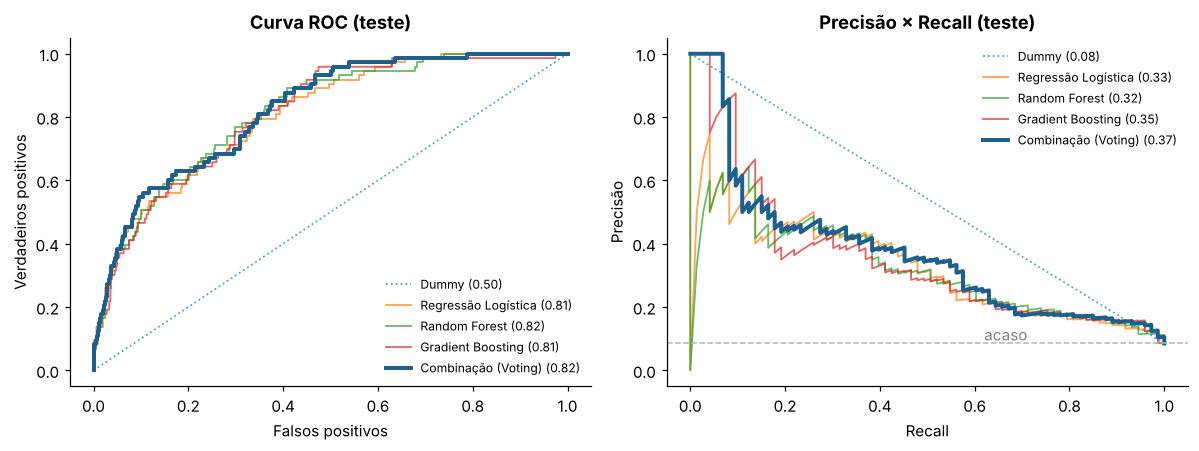

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for nome, pr in probs.items():
    destaque = nome == FINAL
    kw = dict(lw=2.6 if destaque else 1.2, color=COR if destaque else None, alpha=1 if destaque else .7,
              ls=':' if nome == 'Dummy' else '-')
    f, t, _ = roc_curve(yte, pr); ax[0].plot(f, t, label=f'{nome} ({roc_auc_score(yte, pr):.2f})', **kw)
    pr_, rc_, _ = precision_recall_curve(yte, pr)
    ax[1].plot(rc_, pr_, label=f'{nome} ({average_precision_score(yte, pr):.2f})', **kw)
ax[0].set(title='Curva ROC (teste)', xlabel='Falsos positivos', ylabel='Verdadeiros positivos')
ax[1].axhline(yte.mean(), color=CINZA, ls='--', lw=1); ax[1].text(0.62, yte.mean()+.01, 'acaso', color='gray')
ax[1].set(title='Precisão × Recall (teste)', xlabel='Recall', ylabel='Precisão')
for a in ax: a.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig('05_resultados/figuras/curvas_roc_pr.png', bbox_inches='tight'); plt.show()

### Curva de ganho: quantas mortes captamos priorizando os acidentes de maior risco?

Top 10%: 45% | top 20%: 60% | top 30%: 68% das mortes


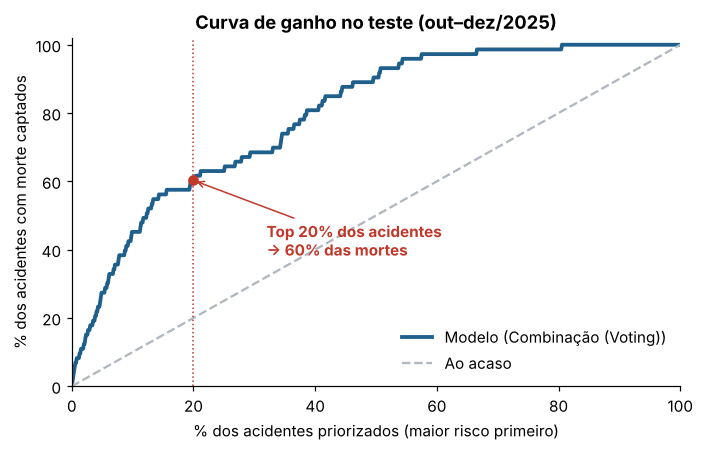

In [8]:
ordem = np.argsort(-probs[FINAL]); y_ord = yte.values[ordem]
frac = np.arange(1, len(y_ord)+1) / len(y_ord); ganho = np.cumsum(y_ord) / y_ord.sum()
ganho20 = ganho[int(np.ceil(.2*len(y_ord))) - 1]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(frac*100, ganho*100, color=COR, lw=2.5, label=f'Modelo ({FINAL})')
ax.plot([0, 100], [0, 100], color=CINZA, ls='--', label='Ao acaso')
ax.axvline(20, color=DESTAQUE, lw=1, ls=':'); ax.scatter([20], [ganho20*100], color=DESTAQUE, zorder=3)
ax.annotate(f'Top 20% dos acidentes\n→ {ganho20:.0%} das mortes', (20, ganho20*100), xytext=(32, ganho20*100-22),
            arrowprops=dict(arrowstyle='->', color=DESTAQUE), color=DESTAQUE, fontweight='bold')
ax.set(title='Curva de ganho no teste (out–dez/2025)', xlabel='% dos acidentes priorizados (maior risco primeiro)',
       ylabel='% dos acidentes com morte captados', xlim=(0, 100), ylim=(0, 102))
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('05_resultados/figuras/curva_ganho.png', bbox_inches='tight'); plt.show()
print(f'Top 10%: {ganho[int(.1*len(y_ord))-1]:.0%} | top 20%: {ganho20:.0%} | top 30%: {ganho[int(.3*len(y_ord))-1]:.0%} das mortes')

## 6. O que o modelo aprendeu: importância das variáveis

Importância por permutação no **teste** (quanto o PR-AUC cai ao embaralhar cada variável original), e razões de chance da regressão logística para leitura direta.

tem_pedestre      0.0752
tipo_acidente     0.0748
tem_moto          0.0596
tem_caminhao      0.0526
tipo_pista        0.0446
hora_cos          0.0324
causa_acidente    0.0179
longitude         0.0159
uso_solo          0.0075
hora_sin          0.0073
sentido_via       0.0046
dia_semana_num    0.0038

Razões de chance (Regressão Logística, com regularização forte) — maiores aumentos de risco.
Categorias: em relação à média; numéricas: por 1 desvio padrão.
cat__tipo_acidente_Colisão frontal            1.59
cat__tipo_pista_Simples                       1.58
num__tem_pedestre                             1.48
num__tem_moto                                 1.47
num__tem_caminhao                             1.42
num__hora_cos                                 1.31
cat__causa_acidente_Transitar na contramão    1.28
cat__br_BR-408                                1.26
cat__uso_solo_Não                             1.25
num__tem_bicicleta                            1.24


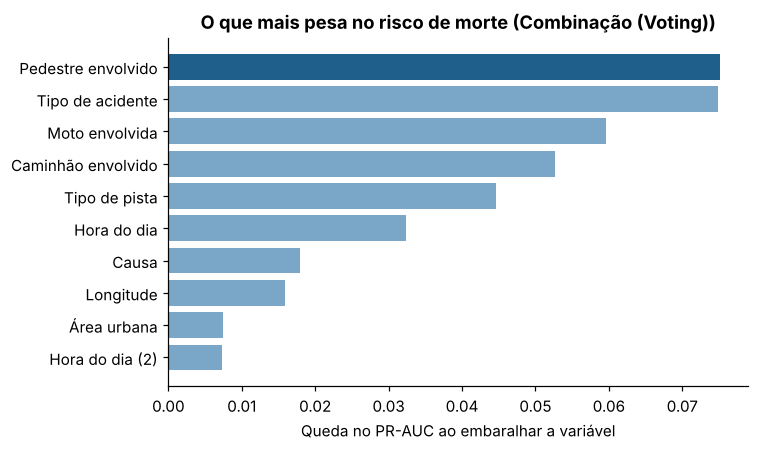

In [9]:
imp = permutation_importance(modelo_final, Xte, yte, scoring='average_precision', n_repeats=15,
                             random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=Xte.columns).sort_values(ascending=False)
nomes = {'tipo_acidente': 'Tipo de acidente', 'tem_pedestre': 'Pedestre envolvido', 'tem_moto': 'Moto envolvida',
         'hora_cos': 'Hora do dia', 'hora_sin': 'Hora do dia (2)', 'tipo_pista': 'Tipo de pista',
         'causa_acidente': 'Causa', 'fase_dia': 'Fase do dia', 'uso_solo': 'Área urbana', 'br': 'Rodovia (BR)',
         'veiculos': 'Nº de veículos', 'pessoas': 'Nº de pessoas', 'km': 'Km', 'latitude': 'Latitude',
         'longitude': 'Longitude', 'delegacia': 'Delegacia', 'tem_caminhao': 'Caminhão envolvido',
         'mes': 'Mês', 'dia_semana_num': 'Dia da semana', 'condicao_metereologica': 'Clima',
         'fim_de_semana': 'Fim de semana', 'tem_onibus': 'Ônibus envolvido', 'tem_bicicleta': 'Bicicleta envolvida',
         'sentido_via': 'Sentido', 'trac_curva': 'Curva'}
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh([nomes.get(i, i) for i in top.index], top.values, color=[COR if v == top.max() else '#7aa6c8' for v in top.values])
ax.set(title=f'O que mais pesa no risco de morte ({FINAL})', xlabel='Queda no PR-AUC ao embaralhar a variável')
plt.tight_layout(); plt.savefig('05_resultados/figuras/importancia_variaveis.png', bbox_inches='tight'); plt.show()
print(imp.head(12).round(4).to_string())

lr = melhores['Regressão Logística'].fit(Xtr, ytr)
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr.named_steps['prep'].get_feature_names_out())
rc = np.exp(coef).sort_values()
print('\nRazões de chance (Regressão Logística, com regularização forte) — maiores aumentos de risco.')
print('Categorias: em relação à média; numéricas: por 1 desvio padrão.')
print(rc.tail(10)[::-1].round(2).to_string())

## 7. Segmentação de municípios: PCA + K-means

Para cada município com **pelo menos 10 acidentes** (amostra mínima para taxas estáveis) calculamos 7 indicadores de risco. As variáveis são padronizadas; o PCA mostra quanta informação cabe em 2 dimensões e serve para visualizar os grupos; o número de grupos *k* é escolhido pelo **coeficiente de silhueta**.

In [10]:
agg = df.groupby('cod_ibge').agg(acidentes=('id', 'size'), pct_morte=('com_morte', 'mean'),
        pct_madrugada=('hora', lambda h: h.between(0, 5).mean()),
        pct_pista_simples=('tipo_pista', lambda t: (t == 'Simples').mean()),
        pct_moto=('tem_moto', 'mean'), pct_pedestre=('tem_pedestre', 'mean'),
        pct_urbano=('uso_solo', lambda u: (u == 'Sim').mean()))
seg = mu.merge(agg.drop(columns='acidentes'), on='cod_ibge')
seg = seg[seg.acidentes >= 10].copy()
seg['log_acid_100mil'] = np.log1p(seg.acidentes_100mil_hab)
VARS = ['log_acid_100mil', 'pct_morte', 'pct_madrugada', 'pct_pista_simples', 'pct_moto', 'pct_pedestre', 'pct_urbano']
Z = StandardScaler().fit_transform(seg[VARS])

pca = PCA(random_state=SEED).fit(Z)
print('Variância explicada acumulada:', np.cumsum(pca.explained_variance_ratio_).round(2))
print(pd.DataFrame(pca.components_[:2].T, index=VARS, columns=['PC1', 'PC2']).round(2))

sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 8)}
inercia = {k: KMeans(k, n_init=20, random_state=SEED).fit(Z).inertia_ for k in range(1, 8)}
print('Silhueta por k:', {k: round(v, 3) for k, v in sil.items()})

Variância explicada acumulada: [0.3  0.51 0.68 0.81 0.91 0.96 1.  ]
                    PC1   PC2
log_acid_100mil   -0.09 -0.24
pct_morte         -0.29  0.66
pct_madrugada     -0.47  0.08
pct_pista_simples -0.31  0.46
pct_moto           0.47  0.26
pct_pedestre       0.23  0.41
pct_urbano         0.57  0.25
Silhueta por k: {2: 0.178, 3: 0.171, 4: 0.182, 5: 0.198, 6: 0.199, 7: 0.192}


In [11]:
# A silhueta fica entre 0,18 e 0,20 de k=4 a k=7 (diferença pequena). k=6 e k=7 criam grupos de 1 município.
# Escolhemos k=4: silhueta próxima da máxima, nenhum grupo com menos de 5 municípios e perfis interpretáveis.
K = 4
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
seg['grupo'] = km.labels_
perfil = seg.groupby('grupo').agg(municipios=('municipio', 'size'), acidentes=('acidentes', 'sum'),
          mortos=('mortos', 'sum'), acid_100mil=('acidentes_100mil_hab', 'median'),
          pct_morte=('pct_morte', 'mean'), pct_madrugada=('pct_madrugada', 'mean'),
          pct_pista_simples=('pct_pista_simples', 'mean'), pct_moto=('pct_moto', 'mean'),
          pct_pedestre=('pct_pedestre', 'mean'), pct_urbano=('pct_urbano', 'mean'))
print(f'k escolhido = {K} (silhueta {sil[K]:.3f})')
print(perfil.round(2).T)
for g in sorted(seg.grupo.unique()):
    print(f'Grupo {g}:', ', '.join(seg[seg.grupo == g].sort_values('acidentes', ascending=False).municipio.head(8)))

k escolhido = 4 (silhueta 0.182)
grupo                    0       1       2       3
municipios           17.00   15.00   10.00    6.00
acidentes          2097.00  333.00  285.00  114.00
mortos              132.00   60.00   34.00   40.00
acid_100mil          68.42   67.11   37.87   30.45
pct_morte             0.09    0.18    0.11    0.33
pct_madrugada         0.08    0.18    0.16    0.11
pct_pista_simples     0.32    0.92    0.05    0.95
pct_moto              0.54    0.37    0.41    0.59
pct_pedestre          0.09    0.05    0.03    0.10
pct_urbano            0.58    0.16    0.18    0.44
Grupo 0: Recife, Petrolina, Jaboatão dos Guararapes, Caruaru, Igarassu, Garanhuns, Serra Talhada, Abreu e Lima
Grupo 1: Arcoverde, São Caitano, Ouricuri, Cabrobó, Agrestina, Sertânia, Caetés, Sanharó
Grupo 2: Moreno, Goiana, São Lourenço da Mata, Cabo de Santo Agostinho, Vitória de Santo Antão, Escada, Palmares, Ipojuca
Grupo 3: Pesqueira, Araripina, Belo Jardim, Carpina, Custódia, Nazaré da Mata


Os grupos recebem nomes de acordo com o perfil (célula abaixo) e são mostrados no plano das duas primeiras componentes principais.

                                                  nome  ...  pct_morte
grupo                                                   ...           
0        Polos urbanos: muito volume, menor letalidade  ...       0.09
1           Interior em pista simples: letalidade alta  ...       0.18
2      Corredores duplicados: letalidade intermediária  ...       0.11
3         Pista simples crítica: 1 em 3 acidentes mata  ...       0.33

[4 rows x 5 columns]


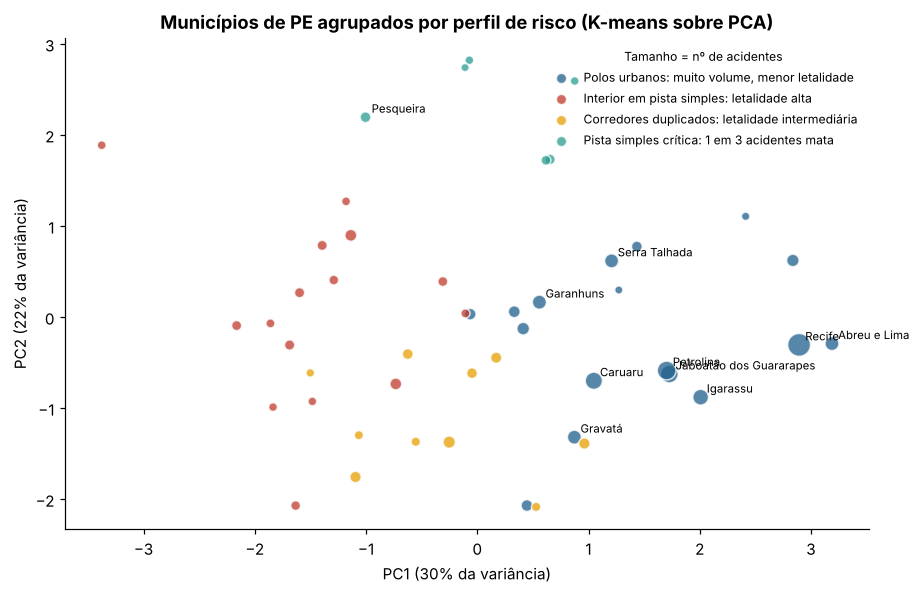

In [12]:
# nomeia os grupos pelo perfil dominante
nome = {}
g_polo = perfil.acidentes.idxmax(); nome[g_polo] = 'Polos urbanos: muito volume, menor letalidade'
resto = perfil.drop(g_polo)
simples = resto[resto.pct_pista_simples > .6].sort_values('pct_morte', ascending=False)
if len(simples): nome[simples.index[0]] = 'Pista simples crítica: 1 em 3 acidentes mata'
for g in simples.index[1:]: nome[g] = 'Interior em pista simples: letalidade alta'
for g in resto.index.difference(simples.index): nome[g] = 'Corredores duplicados: letalidade intermediária'
perfil['nome'] = perfil.index.map(nome)
seg['perfil'] = seg.grupo.map(perfil.nome)
print(perfil[['nome', 'municipios', 'acidentes', 'mortos', 'pct_morte']].round(2))

pcs = pca.transform(Z)[:, :2]
paleta = ['#1f5f8b', '#c0392b', '#e69f00', '#2a9d8f', '#7b4f9e', '#6c757d', '#8c564b']
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for g in sorted(seg.grupo.unique()):
    m = (seg.grupo == g).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=np.sqrt(seg.acidentes[m])*9, color=paleta[g], alpha=.75,
               edgecolor='white', label=perfil.nome[g])
for i, (_, r) in enumerate(seg.iterrows()):
    if r.acidentes >= 80 or r.mortos >= 10:
        ax.annotate(r.municipio, pcs[i], fontsize=7.5, xytext=(4, 3), textcoords='offset points')
ev = pca.explained_variance_ratio_
ax.set(title='Municípios de PE agrupados por perfil de risco (K-means sobre PCA)',
       xlabel=f'PC1 ({ev[0]:.0%} da variância)', ylabel=f'PC2 ({ev[1]:.0%} da variância)')
leg = ax.legend(frameon=False, fontsize=8, loc='best', title='Tamanho = nº de acidentes', title_fontsize=8)
for h in leg.legend_handles: h.set_sizes([45])
plt.tight_layout(); plt.savefig('05_resultados/figuras/clusters_municipios.png', bbox_inches='tight'); plt.show()

## 8. Salvando resultados para a visualização e o README

In [13]:
teste_out = teste[['id', 'data', 'br_nome', 'km', 'municipio', 'tipo_acidente', 'faixa_horaria', 'tipo_pista',
                   'latitude', 'longitude', 'com_morte']].copy()
teste_out['prob_morte'] = probs[FINAL].round(4); teste_out['alerta'] = pred
teste_out.to_csv('05_resultados/previsoes_teste.csv', index=False)
teste_res.round(4).to_csv('05_resultados/metricas_teste.csv')
cv_final.round(4).to_csv('05_resultados/metricas_validacao_cruzada.csv')
seg[['cod_ibge', 'municipio', 'acidentes', 'mortos'] + VARS + ['grupo', 'perfil']].round(4) \
   .to_csv('05_resultados/segmentacao_municipios.csv', index=False)
print(os.listdir('05_resultados'))

['previsoes_teste.csv', 'metricas_teste.csv', 'figuras', 'segmentacao_municipios.csv', 'metricas_validacao_cruzada.csv']


## 9. Visualização final (Data Storytelling)

Um painel único que conta a história em 4 atos: **o problema → onde o risco está → o que o modelo entrega → onde agir.**

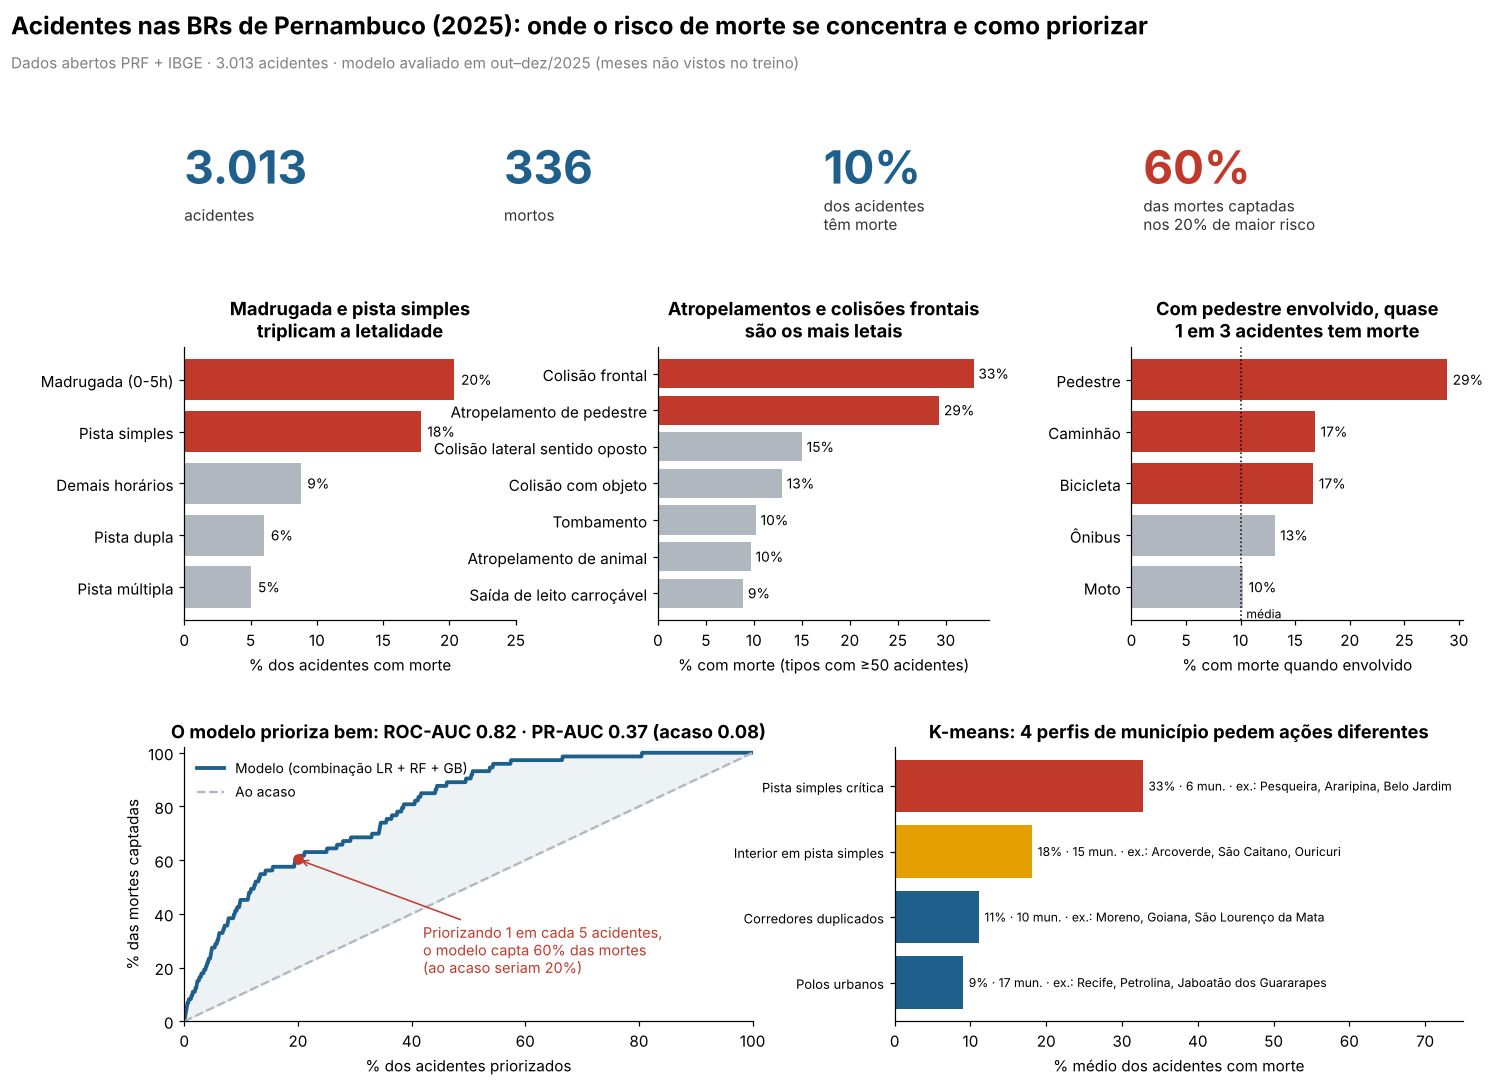

In [14]:
fig = plt.figure(figsize=(15, 10.5)); gs = fig.add_gridspec(3, 6, height_ratios=[.32, 1, 1], hspace=.6, wspace=1.5)
fig.suptitle('Acidentes nas BRs de Pernambuco (2025): onde o risco de morte se concentra e como priorizar',
             fontsize=16, fontweight='bold', x=.02, ha='left', y=.985)
fig.text(.02, .935, 'Dados abertos PRF + IBGE · 3.013 acidentes · modelo avaliado em out–dez/2025 (meses não vistos no treino)',
         fontsize=10, color='gray')

# Ato 1: KPIs
kpis = [(f'{len(oc):,}'.replace(',', '.'), 'acidentes'), (f'{int(oc.mortos.sum())}', 'mortos'),
        (f'{oc.com_morte.mean():.0%}', 'dos acidentes\ntêm morte'), (f'{ganho20:.0%}', 'das mortes captadas\nnos 20% de maior risco')]
a = fig.add_subplot(gs[0, :]); a.axis('off')
for i, (v, t) in enumerate(kpis):
    a.text(i*.25, .6, v, fontsize=30, fontweight='bold', color=DESTAQUE if i == 3 else COR, va='center', transform=a.transAxes)
    a.text(i*.25, .05, t, fontsize=10, color='#333', va='center', transform=a.transAxes)

# Ato 2: onde o risco está
a = fig.add_subplot(gs[1, 0:2])
grp = pd.concat([oc.groupby('madrugada').com_morte.mean(), oc.groupby('tipo_pista').com_morte.mean().rename(lambda s: f'Pista {s.lower()}')])
grp = grp.sort_values()
a.barh(grp.index, grp.values*100, color=[DESTAQUE if v > .15 else CINZA for v in grp.values])
for y, v in enumerate(grp.values): a.text(v*100+.5, y, f'{v:.0%}', va='center', fontsize=9)
a.set(title='Madrugada e pista simples\ntriplicam a letalidade', xlabel='% dos acidentes com morte'); a.set_xlim(0, 25)

a = fig.add_subplot(gs[1, 2:4])
t = df.groupby('tipo_acidente').agg(n=('id', 'size'), m=('com_morte', 'mean')).query('n >= 50').sort_values('m').tail(7)
a.barh(t.index, t.m*100, color=[DESTAQUE if v > .2 else CINZA for v in t.m])
for y, v in enumerate(t.m): a.text(v*100+.5, y, f'{v:.0%}', va='center', fontsize=9)
a.set(title='Atropelamentos e colisões frontais\nsão os mais letais', xlabel='% com morte (tipos com ≥50 acidentes)')

a = fig.add_subplot(gs[1, 4:6])
envolv = {'Pedestre': 'tem_pedestre', 'Moto': 'tem_moto', 'Caminhão': 'tem_caminhao', 'Bicicleta': 'tem_bicicleta', 'Ônibus': 'tem_onibus'}
e = pd.Series({k: df[df[c] == 1].com_morte.mean() for k, c in envolv.items()}).sort_values()
a.barh(e.index, e.values*100, color=[DESTAQUE if v > .15 else CINZA for v in e.values])
a.axvline(df.com_morte.mean()*100, color='k', ls=':', lw=1); a.text(df.com_morte.mean()*100+.5, -.6, 'média', fontsize=8)
for y, v in enumerate(e.values): a.text(v*100+.5, y, f'{v:.0%}', va='center', fontsize=9)
a.set(title='Com pedestre envolvido, quase\n1 em 3 acidentes tem morte', xlabel='% com morte quando envolvido')

# Ato 3: o modelo
a = fig.add_subplot(gs[2, 0:3])
a.plot(frac*100, ganho*100, color=COR, lw=2.5, label='Modelo (combinação LR + RF + GB)')
a.plot([0, 100], [0, 100], color=CINZA, ls='--', label='Ao acaso')
a.fill_between(frac*100, frac*100, ganho*100, color=COR, alpha=.08)
a.scatter([20], [ganho20*100], color=DESTAQUE, zorder=3)
a.annotate(f'Priorizando 1 em cada 5 acidentes,\no modelo capta {ganho20:.0%} das mortes\n(ao acaso seriam 20%)',
           (20, ganho20*100), xytext=(42, 18), arrowprops=dict(arrowstyle='->', color=DESTAQUE), color=DESTAQUE, fontsize=9.5)
a.set(title=f'O modelo prioriza bem: ROC-AUC {roc_auc_score(yte, probs[FINAL]):.2f} · PR-AUC {average_precision_score(yte, probs[FINAL]):.2f} (acaso {yte.mean():.2f})',
      xlabel='% dos acidentes priorizados', ylabel='% das mortes captadas', xlim=(0, 100), ylim=(0, 102))
a.legend(frameon=False, loc='upper left', fontsize=9)

# Ato 4: onde agir
a = fig.add_subplot(gs[2, 3:6])
pf = perfil.sort_values('pct_morte')
cores_p = [DESTAQUE if v == pf.pct_morte.max() else ('#e69f00' if v > .15 else COR) for v in pf.pct_morte]
curto = pf.nome.str.split(':').str[0]
a.barh(curto, pf.pct_morte*100, color=cores_p)
for y, (_, r) in enumerate(pf.iterrows()):
    ex = ', '.join(seg[seg.grupo == r.name].sort_values('acidentes', ascending=False).municipio.head(3))
    a.text(r.pct_morte*100+.7, y, f'{r.pct_morte:.0%} · {int(r.municipios)} mun. · ex.: {ex}', va='center', fontsize=8)
a.set(title='K-means: 4 perfis de município pedem ações diferentes', xlabel='% médio dos acidentes com morte'); a.set_xlim(0, 75)
a.tick_params(axis='y', labelsize=8.5)
plt.savefig('05_resultados/figuras/painel_storytelling.png', bbox_inches='tight', dpi=150); plt.show()

## 10. Conclusões da modelagem

Os números exatos estão nas saídas acima e no `README.md`. Em resumo:

- As diferenças de letalidade por horário e tipo de pista são **estatisticamente significativas** (qui-quadrado, p < 0,001).
- Todos os modelos superam com folga a linha de base; o modelo final, escolhido pela validação cruzada, foi avaliado uma única vez em meses futuros (out–dez).
- Ao sinalizar os 20% de acidentes de maior risco, o modelo concentra uma fração muito maior das mortes do que uma escolha ao acaso — útil para **priorizar atendimento e fiscalização**.
- **Tipo de acidente, pedestre/moto envolvidos, horário e tipo de pista** são os fatores que mais pesam — todos acionáveis (passarelas e iluminação, fiscalização noturna, duplicação, campanhas para motociclistas).
- A segmentação mostra que **o mesmo plano não serve para todos os municípios**: a região metropolitana tem muito volume e menor letalidade; o interior em pista simples tem poucos acidentes, mas muito mais letais.

**Limitações:** um único ano de dados (2025); o modelo prevê gravidade *dado que* o acidente aconteceu (não prevê onde acontecerá o próximo); a causa do acidente é registrada pela PRF após a ocorrência, então em um uso em tempo real ela precisaria ser substituída por informações do chamado.